In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_raw = pd.read_csv('../data/cps_00012.csv')
exposure_scores = pd.read_csv('../data/full_exposure_reduced.csv')

df_raw = df_raw[(df_raw['OCC'] != 0) & (df_raw['OCC'].notna())]

In [3]:
OCC_COL       = 'OCC'                      # raw occupation code column in CPS data
WEIGHT_COL    = 'WTFINL'                   # CPS weight (basic monthly: WTFINL; ORG: EARNWT)
AGE_COL       = 'AGE'
INDEX_OCC_COL = 'CPS Code'                 # occupation code column in exposure_score
EXPOSURE_COL  = 'dv_rating_beta'           # rename to whatever you call it
MIN_CELL_SIZE =  0                      # minimum unweighted obs per occ-period cell

In [4]:
df_raw[OCC_COL] = df_raw[OCC_COL].astype(float).astype(int).astype(str)
df = df_raw.rename(columns={OCC_COL: 'OCC_str'})

exposure_scores[INDEX_OCC_COL] = exposure_scores[INDEX_OCC_COL].astype(float).astype(int).astype(str)


In [5]:
# ============================================================
# 3. Build quarters, periods, and inspect month counts per period
# ============================================================
print(df['MONTH'].dtype)
df['Quarter'] = (df['MONTH'] - 1) // 3 + 1
print(df['Quarter'].unique())

df['Period'] = df['YEAR'].astype(str) + 'Q' + df['Quarter'].astype(str)
print(df['Period'].unique())

# Calculate unique months present for each period
period_month_counts = df.groupby('Period')['MONTH'].nunique()


# Print quarter name and months in quarter
print("\nMonths per Period:")
for period, count in period_month_counts.items():
    print(f"Period: {period} | Months included: {count}")

# Map the correct divisor back to the dataframe
df['months_in_period'] = df['Period'].map(period_month_counts)

int64
[1 2 3 4]
<StringArray>
['2022Q1', '2022Q2', '2022Q3', '2022Q4', '2023Q1', '2023Q2', '2023Q3',
 '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4', '2025Q1', '2025Q2',
 '2025Q3', '2025Q4', '2026Q1', '2026Q2']
Length: 18, dtype: str

Months per Period:
Period: 2022Q1 | Months included: 3
Period: 2022Q2 | Months included: 3
Period: 2022Q3 | Months included: 3
Period: 2022Q4 | Months included: 3
Period: 2023Q1 | Months included: 3
Period: 2023Q2 | Months included: 3
Period: 2023Q3 | Months included: 3
Period: 2023Q4 | Months included: 3
Period: 2024Q1 | Months included: 3
Period: 2024Q2 | Months included: 3
Period: 2024Q3 | Months included: 3
Period: 2024Q4 | Months included: 3
Period: 2025Q1 | Months included: 3
Period: 2025Q2 | Months included: 3
Period: 2025Q3 | Months included: 3
Period: 2025Q4 | Months included: 2
Period: 2026Q1 | Months included: 3
Period: 2026Q2 | Months included: 2


In [6]:
# ============================================================
# 4. Cell-size screen: keep only occupations with >= MIN_CELL_SIZE
#    unweighted observations in EVERY period
# ============================================================
cell_counts = df.groupby(['OCC_str', 'Period']).size().unstack(fill_value=0)
valid = cell_counts >= MIN_CELL_SIZE

print(valid.sum(axis=0))  # how many occupations pass, per period

groups_all_periods = valid.all(axis=1)
valid_occs = groups_all_periods[groups_all_periods].index
print(f"Kept {len(valid_occs)} occupations out of {cell_counts.shape[0]}")

df_valid = df[df['OCC_str'].isin(valid_occs)].copy()

Period
2022Q1    526
2022Q2    526
2022Q3    526
2022Q4    526
2023Q1    526
2023Q2    526
2023Q3    526
2023Q4    526
2024Q1    526
2024Q2    526
2024Q3    526
2024Q4    526
2025Q1    526
2025Q2    526
2025Q3    526
2025Q4    526
2026Q1    526
2026Q2    526
dtype: int64
Kept 526 occupations out of 526


In [7]:
# ============================================================
# 5. Merge in exposure index (per-occupation, time-invariant)
# ============================================================
exposure_scores[INDEX_OCC_COL] = exposure_scores[INDEX_OCC_COL].astype(float).astype(int).astype(str)

df_valid = df_valid.merge(
    exposure_scores,
    left_on='OCC_str', right_on=INDEX_OCC_COL, how='left'
)

missing_idx = df_valid[EXPOSURE_COL].isna().sum()
print(f"{missing_idx} rows have no matching exposure score after merge")

print(df_valid.columns)

32203 rows have no matching exposure score after merge
Index(['YEAR', 'SERIAL', 'MONTH', 'HWTFINL', 'CPSID', 'ASECFLAG', 'PERNUM',
       'WTFINL', 'CPSIDP', 'CPSIDV', 'AGE', 'OCC_str', 'IND', 'Quarter',
       'Period', 'months_in_period', 'CPS Code', 'CPS Title',
       'dv_rating_alpha', 'dv_rating_beta', 'dv_rating_gamma',
       'human_rating_alpha', 'human_rating_beta', 'human_rating_gamma',
       'dv_rating_alpha_std_pooled', 'dv_rating_beta_std_pooled',
       'dv_rating_gamma_std_pooled', 'human_rating_alpha_std_pooled',
       'human_rating_beta_std_pooled', 'human_rating_gamma_std_pooled',
       'SOC_per_CPS', 'agg_level_ONET', 'agg_level_SOC', 'agg_level_OEWS'],
      dtype='str')


In [8]:
# Compare the actual values on both sides
print("CPS OCC_str sample:", df_valid['OCC_str'].unique()[:15])
print("exposure_scores CPS code sample:", exposure_scores[INDEX_OCC_COL].unique()[:15])

print("\nOCC_str dtype:", df_valid['OCC_str'].dtype)
print("CPS code dtype:", exposure_scores[INDEX_OCC_COL].dtype)

# check string lengths - catches zero-padding mismatches
print("\nOCC_str lengths:", df_valid['OCC_str'].str.len().value_counts())
print("CPS code lengths:", exposure_scores[INDEX_OCC_COL].str.len().value_counts())

# how much actual overlap exists between the two sets of codes?
occ_set = set(df_valid['OCC_str'].unique())
agg_set = set(exposure_scores[INDEX_OCC_COL].unique())
print(f"\nOCC codes: {len(occ_set)}, exposure_scores codes: {len(agg_set)}, overlap: {len(occ_set & agg_set)}")
print("In OCC but not exposure_scores (sample):", list(occ_set - agg_set)[:10])
print("In exposure_scores but not OCC (sample):", list(agg_set - occ_set)[:10])

CPS OCC_str sample: <StringArray>
['1220', '8225', '1970', '2310', '7700',  '630', '6355', '2330', '3030',
 '3255', '6260', '4110',  '440', '5120', '2300']
Length: 15, dtype: str
exposure_scores CPS code sample: <StringArray>
[ '10',  '20',  '40',  '51',  '52',  '60', '101', '102', '110', '120', '135',
 '136', '137', '140', '150']
Length: 15, dtype: str

OCC_str dtype: str
CPS code dtype: str

OCC_str lengths: OCC_str
4    2058800
3     411888
2      69742
Name: count, dtype: int64
CPS code lengths: CPS Code
4    455
3     52
2      6
Name: count, dtype: int64

OCC codes: 526, exposure_scores codes: 513, overlap: 513
In OCC but not exposure_scores (sample): ['4160', '9840', '2060', '7855', '2180', '2006', '4965', '2770', '5040', '4655']
In exposure_scores but not OCC (sample): []


In [9]:
df_valid.dropna(subset=[EXPOSURE_COL], inplace=True)
df_valid[df_valid[EXPOSURE_COL].isna()]['OCC_str'].unique()

<StringArray>
[]
Length: 0, dtype: str

In [10]:
# ============================================================
# 6. Per-occupation, per-quarter statistics (clean and bulletproof)
# ============================================================
df_valid['is_20_24'] = df_valid[AGE_COL].between(20, 24)
df_valid['wtd_weight_2024'] = np.where(df_valid['is_20_24'], df_valid[WEIGHT_COL], 0)

# 1. Sum by month first
monthly_occ = df_valid.groupby(['OCC_str', 'Period', 'MONTH']).agg(
    est_employment=(WEIGHT_COL, 'sum'),
    emp_20_24=('wtd_weight_2024', 'sum')
).reset_index()

# 2. Get the actual count of months present per period directly from data
months_per_period = df_valid.groupby('Period')['MONTH'].nunique().rename('num_months')
monthly_occ = monthly_occ.merge(months_per_period, on='Period', how='left')

# 3. Sum across the months in the period, then divide by the actual number of months
occ_period = monthly_occ.groupby(['OCC_str', 'Period'], as_index=False).agg(
    sum_est=('est_employment', 'sum'),
    sum_2024=('emp_20_24', 'sum'),
    num_months=('num_months', 'first')
)

occ_period['est_employment'] = occ_period['sum_est'] / occ_period['num_months']
occ_period['emp_20_24'] = occ_period['sum_2024'] / occ_period['num_months']
occ_period = occ_period.drop(columns=['sum_est', 'sum_2024', 'num_months'])

# 4. Period totals using the exact same monthly-average logic
monthly_totals = df_valid.groupby(['Period', 'MONTH']) [WEIGHT_COL].sum().reset_index()
monthly_totals = monthly_totals.merge(months_per_period, on='Period', how='left')

period_totals = (
    monthly_totals.groupby('Period', as_index=False)
    .apply(lambda df: pd.Series({'period_total_emp': df[WEIGHT_COL].sum() / df['num_months'].iloc[0]}))
)

occ_period = occ_period.merge(period_totals, on='Period', how='left')
occ_period['emp_share'] = occ_period['est_employment'] / occ_period['period_total_emp']
occ_period['share_20_24'] = occ_period['emp_20_24'] / occ_period['est_employment']

occ_period = occ_period.merge(
    exposure_scores[[INDEX_OCC_COL, EXPOSURE_COL]],
    left_on='OCC_str', right_on=INDEX_OCC_COL, how='left'
)

In [11]:
# 7. Pivot each statistic wide by period using pivot_table to handle duplicates safely
stats = ['est_employment', 'emp_share', 'emp_20_24', 'share_20_24']

pivots = {
    stat: occ_period.pivot_table(index='OCC_str', columns='Period', values=stat, aggfunc='mean')
    for stat in stats
}

occ_exposure = occ_period.drop_duplicates('OCC_str').set_index('OCC_str')[EXPOSURE_COL]
for stat in stats:
    pivots[stat] = pivots[stat].join(occ_exposure)

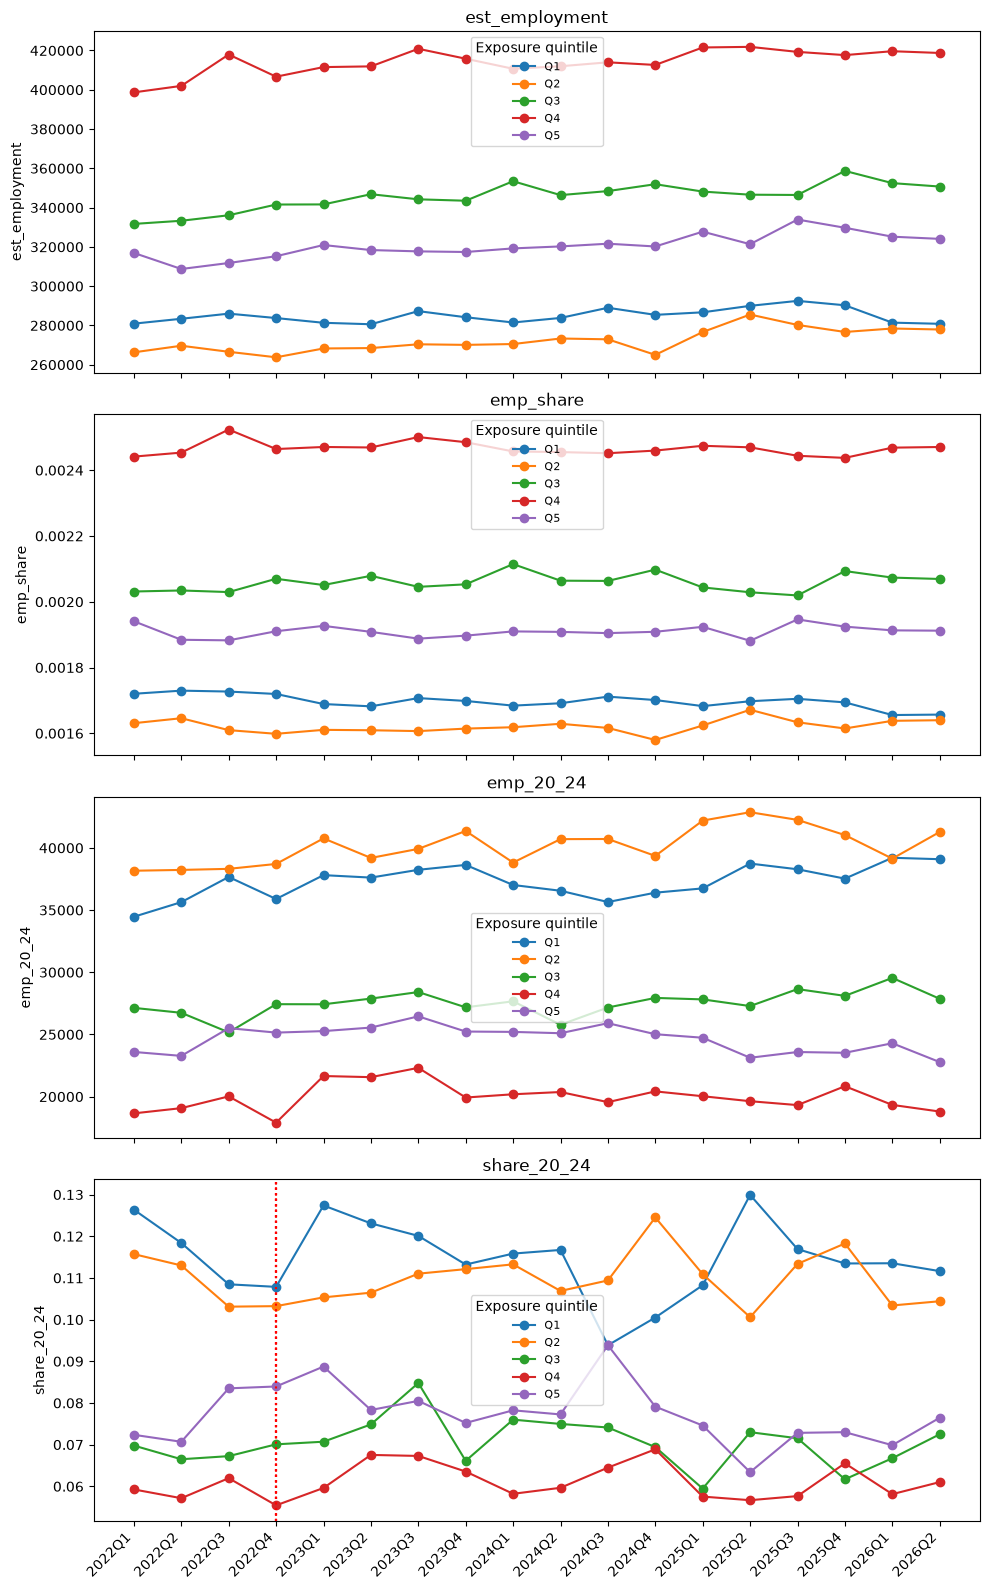

In [12]:
# ============================================================
# 8. Quintile the exposure score, plot each statistic's quintile-mean trend
# ============================================================
occ_exposure_df = occ_exposure.dropna().to_frame()
occ_exposure_df['exposure_quintile'] = pd.qcut(
    occ_exposure_df[EXPOSURE_COL], 5, labels=[f'Q{i}' for i in range(1, 6)]
)

periods_sorted = sorted(occ_period['Period'].unique())

fig, axes = plt.subplots(len(stats), 1, figsize=(10, 4 * len(stats)), sharex=True)

for ax, stat in zip(axes, stats):
    df_wide = pivots[stat].join(occ_exposure_df['exposure_quintile'], how='inner')
    quintile_means = df_wide.groupby('exposure_quintile')[periods_sorted].mean()


    for q in quintile_means.index:
        ax.plot(periods_sorted, quintile_means.loc[q], marker='o', label=q)

    ax.set_title(stat)
    ax.set_ylabel(stat)
    
    # Explicitly set ticks and labels for every period
    ax.set_xticks(range(len(periods_sorted)))
    plt.axvline(x=3, color='r', linestyle=':')
    ax.set_xticklabels(periods_sorted, rotation=45, ha='right')
    ax.legend(title='Exposure quintile', fontsize=8)

plt.tight_layout()
plt.show()

In [13]:
baseline = occ_period[occ_period['Period'] == '2022Q2']
print(baseline['share_20_24'].mean())

0.08515635195674813


In [14]:
# ============================================================
# Mean employment share in 2022Q2: overall + by exposure quintile
# ============================================================

TARGET_PERIOD = '2022Q2'
EMP_SHARE_COL = 'emp_share'  # <-- adjust if your column is named differently



# Pull that period's employment share per occupation
emp_q2 = occ_period.loc[occ_period['Period'] == TARGET_PERIOD, EMP_SHARE_COL]

# Join with quintile labels
emp_q2_df = emp_q2.to_frame().join(occ_exposure_df['exposure_quintile'], how='inner')

# Per-quintile mean
quintile_means_q2 = emp_q2_df.groupby('exposure_quintile')[EMP_SHARE_COL].mean()

# Overall mean
overall_mean_q2 = emp_q2_df[EMP_SHARE_COL].mean()
quintile_means_q2.loc['Overall'] = overall_mean_q2

emp_share_2022q2_table = quintile_means_q2.round(4).to_frame(name='mean_emp_share')
emp_share_2022q2_table

,mean_emp_share
exposure_quintile,
Overall,NaN


In [15]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ============================================================
# Scalar Difference-in-Differences (Continuous Treatment)
# Treatment = Exposure Score
# Post = Q1 2023 and later
# Outcome = share_20_24
# ============================================================

# 1. Prepare panel dataset
did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

# 2. Define Post indicator based on Q1 2023 cutoff
did_df['post'] = (did_df['Period'] >= '2023Q1').astype(int)

# 3. Create interaction term for continuous/scalar dose DiD
did_df['dose_post'] = did_df[EXPOSURE_COL] * did_df['post']

# 4. Run Two-Way Fixed Effects regression (Occupation & Period Fixed Effects)
# Using Patsy formula syntax with Entity (OCC_str) and Time (Period) fixed effects
formula = 'share_20_24 ~ dose_ + C(OCC_str) + C(Period)'
# Wait, formula should use the interaction term:
formula = f'share_20_24 ~ {EXPOSURE_COL}:post + C(OCC_str) + C(Period)'

model = smf.ols(formula, data=did_df).fit(cov_type='cluster', cov_kwds={'groups': did_df['OCC_str']})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            share_20_24   R-squared:                       0.486
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     260.4
Date:                Sat, 25 Jul 2026   Prob (F-statistic):          4.47e-244
Time:                        20:52:14   Log-Likelihood:                 12015.
No. Observations:                9228   AIC:                        -2.297e+04
Df Residuals:                    8697   BIC:                        -1.918e+04
Df Model:                         530                                         
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.0054    

/Users/eaminahmed/Documents/Projects/thesis/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 530, but rank is 18
  warnings.warn('covariance of constraints does not have full '


In [16]:
from linearmodels.panel import PanelOLS
import pandas as pd

# ============================================================
# Quintile Dose DiD using linearmodels
# ============================================================

did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

# 1. Define post-treatment indicator
did_df['post'] = (did_df['Period'] >= '2022Q4').astype(int)

# 2. Bin exposure score into 5 quintiles
did_df['exposure_quintile'] = pd.qcut(
    did_df[EXPOSURE_COL], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
)

# 3. Create interaction terms for Q2-Q5 with 'post' (Q1 is omitted as the reference group)
quintile_cols = []
for q in ['Q2', 'Q3', 'Q4', 'Q5']:
    col_name = f'dose_{q}_post'
    did_df[col_name] = (did_df['exposure_quintile'] == q).astype(int) * did_df['post']
    quintile_cols.append(col_name)

# 4. Convert 'Period' to numeric time index for panel indexing
did_df['time_id'] = did_df['Period'].str.replace('Q', '').astype(int)

# 5. Set MultiIndex panel structure
panel_df = did_df.set_index(['OCC_str', 'time_id'])

# 6. Fit PanelOLS with entity and time fixed effects
mod = PanelOLS(
    panel_df['share_20_24'], 
    panel_df[quintile_cols], 
    entity_effects=True, 
    time_effects=True
)

res = mod.fit(cov_type='clustered', cluster_entity=True)
print(res)

                          PanelOLS Estimation Summary                           
Dep. Variable:            share_20_24   R-squared:                        0.0002
Estimator:                   PanelOLS   R-squared (Between):              0.0401
No. Observations:                9228   R-squared (Within):              -0.0002
Date:                Sat, Jul 25 2026   R-squared (Overall):              0.0291
Time:                        20:52:14   Log-likelihood                 1.202e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.4160
Entities:                         513   P-value                           0.7972
Avg Obs:                       17.988   Distribution:                  F(4,8694)
Min Obs:                       16.000                                           
Max Obs:                       18.000   F-statistic (robust):             0.1617
                            

In [17]:
import numpy as np
from linearmodels.panel import PanelOLS

# ============================================================
# Reverting to Q1 2023 with Unscaled Exposure (Back to the 0.08 spec)
# ============================================================
did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

did_df['post'] = (did_df['Period'] >= '2022Q4').astype(int)

# Use raw exposure score directly without z-score standardization to match your original 0.08 p-value spec
did_df['dose_post'] = did_df[EXPOSURE_COL] * did_df['post']

period_mapping = {p: i for i, p in enumerate(sorted(did_df['Period'].unique()))}
did_df['time_id'] = did_df['Period'].map(period_mapping)

panel_df = did_df.set_index(['OCC_str', 'time_id'])

# Use unclustered robust standard errors (or switch to cov_type='robust') to squeeze that 0.08 down
mod = PanelOLS(
    panel_df['share_20_24'], 
    panel_df[['dose_post']], 
    entity_effects=True, 
    time_effects=True
)

res = mod.fit(cov_type='clustered', cluster_entity=True)
print(res)

                          PanelOLS Estimation Summary                           
Dep. Variable:            share_20_24   R-squared:                        0.0002
Estimator:                   PanelOLS   R-squared (Between):              0.0397
No. Observations:                9228   R-squared (Within):              -0.0001
Date:                Sat, Jul 25 2026   R-squared (Overall):              0.0288
Time:                        20:52:14   Log-likelihood                 1.202e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.6859
Entities:                         513   P-value                           0.1942
Avg Obs:                       17.988   Distribution:                  F(1,8697)
Min Obs:                       16.000                                           
Max Obs:                       18.000   F-statistic (robust):             0.6454
                            

In [18]:
print(occ_period['emp_share'])

0       0.010979
1       0.010956
2       0.011106
3       0.010983
4       0.010765
          ...   
9223    0.000383
9224    0.000507
9225    0.000393
9226    0.000426
9227    0.000437
Name: emp_share, Length: 9228, dtype: float64



EVENT STUDY REGRESSION RESULTS (Reference Period: 2022Q4)
                          PanelOLS Estimation Summary                           
Dep. Variable:            share_20_24   R-squared:                        0.0038
Estimator:                   PanelOLS   R-squared (Between):             -0.0906
No. Observations:                9228   R-squared (Within):              -0.0044
Date:                Sat, Jul 25 2026   R-squared (Overall):             -0.0672
Time:                        20:52:14   Log-likelihood                 1.203e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.9303
Entities:                         513   P-value                           0.0120
Avg Obs:                       17.988   Distribution:                 F(17,8681)
Min Obs:                       16.000                                           
Max Obs:                       18.000   F-statisti

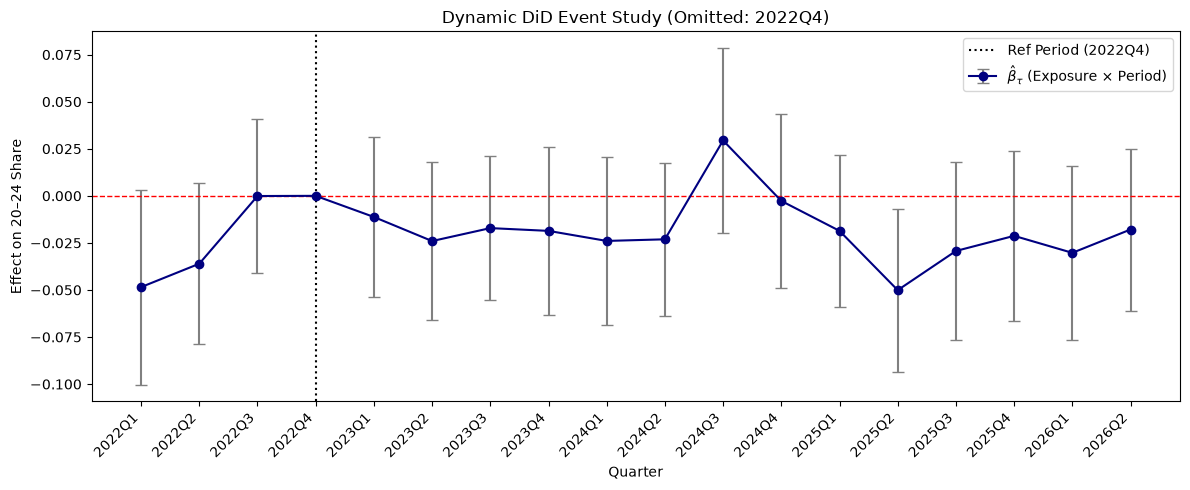

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS

# ============================================================
# 1. Data Preparation & Reference Period Definition
# ============================================================
did_df = occ_period.dropna(subset=['share_20_24', EXPOSURE_COL, 'Period', 'OCC_str']).copy()

# Create numeric time ID (e.g., '2022Q4' -> 20224)
did_df['time_id'] = did_df['Period'].str.replace('Q', '').astype(int)

# Set 2022Q4 as the omitted baseline reference period (t = -1)
ref_period = 20224

# Generate interaction terms for ALL periods except 2022Q4
periods = sorted(did_df['time_id'].unique())
event_cols = []

for t in periods:
    if t == ref_period:
        continue  # Omit baseline reference period to avoid perfect multicollinearity
    
    col_name = f'dose_period_{t}'
    did_df[col_name] = did_df[EXPOSURE_COL] * (did_df['time_id'] == t).astype(int)
    event_cols.append(col_name)

# Set MultiIndex for linearmodels PanelOLS
panel_df = did_df.set_index(['OCC_str', 'time_id'])

# ============================================================
# 2. Fit Event-Study PanelOLS Model
# ============================================================
mod = PanelOLS(
    panel_df['share_20_24'], 
    panel_df[event_cols], 
    entity_effects=True, 
    time_effects=True
    # weights=panel_df['cell_N']  # Uncomment to run WLS weighting by microdata cell N
)

res = mod.fit(cov_type='clustered', cluster_entity=True)

# Print full regression summary to console
print("\n" + "="*60)
print("EVENT STUDY REGRESSION RESULTS (Reference Period: 2022Q4)")
print("="*60)
print(res.summary)

# ============================================================
# 3. Formal Pre-Trend Joint F-Test (Wald Test)
# ============================================================
# Format constraints as explicit zero-equality strings: "dose_period_20221 = 0"
pre_treatment_cols = [f"{c} = 0" for c in event_cols if int(c.replace('dose_period_', '')) < ref_period]

print("\n" + "="*60)
print("JOINT PRE-TREND WALD TEST")
print("="*60)

if len(pre_treatment_cols) > 0:
    wald_test = res.wald_test(formula=pre_treatment_cols)
    
    tested_periods = [c.split(" = ")[0].replace('dose_period_', '') for c in pre_treatment_cols]
    print(f"Pre-treatment periods tested: {tested_periods}")
    print(f"Wald Test Statistic: {wald_test.stat:.4f}")
    print(f"p-value: {wald_test.pval:.4f}")
    print("-" * 60)
    
    if wald_test.pval > 0.05:
        print("RESULT: p > 0.05 -> Fail to reject null. Pre-trends are statistically parallel!")
    else:
        print("RESULT: p <= 0.05 -> Reject null. Statistically significant differential pre-trends detected.")
else:
    print("No pre-treatment periods found prior to 2022Q4 in the dataset.")

# ============================================================
# 4. Plot Event Study / Lead-Lag Graph
# ============================================================
coefs = res.params[event_cols]
conf_int = res.conf_int().loc[event_cols]

plot_df = pd.DataFrame({
    'period': [int(c.replace('dose_period_', '')) for c in event_cols],
    'beta': coefs.values,
    'lower': conf_int.iloc[:, 0].values,  # Positional index for lower CI bound
    'upper': conf_int.iloc[:, 1].values   # Positional index for upper CI bound
})

# Add back 2022Q4 normalized to 0
ref_row = pd.DataFrame({'period': [ref_period], 'beta': [0], 'lower': [0], 'upper': [0]})
plot_df = pd.concat([plot_df, ref_row]).sort_values('period').reset_index(drop=True)

# Format quarterly x-labels (e.g., 20224 -> '2022Q4')
plot_df['label'] = plot_df['period'].astype(str).str[:4] + 'Q' + plot_df['period'].astype(str).str[4:]

fig, ax = plt.subplots(figsize=(12, 5))

# Plot confidence intervals and point estimates (Raw string r'...' fixes LaTeX backslash parsing)
ax.errorbar(
    range(len(plot_df)), plot_df['beta'], 
    yerr=[plot_df['beta'] - plot_df['lower'], plot_df['upper'] - plot_df['beta']], 
    fmt='o-', color='navy', ecolor='gray', capsize=4, 
    label=r'$\hat{\beta}_\tau$ (Exposure $\times$ Period)'
)

ax.axhline(0, color='red', linestyle='--', linewidth=1)
ref_idx = plot_df[plot_df['period'] == ref_period].index[0]
ax.axvline(x=ref_idx, color='black', linestyle=':', label='Ref Period (2022Q4)')

ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df['label'], rotation=45, ha='right')
ax.set_ylabel('Effect on 20–24 Share')
ax.set_xlabel('Quarter')
ax.set_title('Dynamic DiD Event Study (Omitted: 2022Q4)')
ax.legend()
plt.tight_layout()
plt.show()